# Analysis work for APG first track testing

## setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pathlib as path
from scipy.signal import savgol_filter



In [2]:
# not in globals check lets it not re import all the data every jupter run, much faster
# restart kernal if u want to truely reload the data
if "df" not in globals():
    df = pd.read_csv(
        "CSV/STAG12-24.10.2026-WetEndurance.csv",
        skiprows=14,
        low_memory=False
    )

    units = dict(zip(df.columns, df.iloc[0].tolist()))
    df = df.drop(index=0).reset_index(drop=True)
    df = df.apply(pd.to_numeric, errors="coerce")


print(units)
df.head(10)

{'Time': 's', 'Distance': 'm', 'G Force Lat': 'G', 'G Force Long': 'G', 'G Force Vert': 'G', '5V Aux Supply': 'V', '8V Aux Supply': 'V', 'Comms RS232 Diag': nan, 'GPS Sats Used': nan, 'GPS Altitude': 'm', 'GPS Latitude': 'deg', 'GPS Longitude': 'deg', 'GPS Heading': 'deg', 'GPS Time': nan, 'GPS Date': nan, 'GPS Speed': 'km/h', 'PDM Output 1 Current': 'A', 'PDM Output 2 Current': 'A', 'PDM Output 3 Current': 'A', 'PDM Output 4 Current': 'A', 'PDM Output 5 Current': 'A', 'PDM Output 6 Current': 'A', 'PDM Output 7 Current': 'A', 'PDM Output 8 Current': 'A', 'PDM Output 9 Current': 'A', 'PDM Output 10 Current': 'A', 'PDM Output 11 Current': 'A', 'PDM Output 12 Current': 'A', 'PDM Output 13 Current': 'A', 'PDM Output 14 Current': 'A', 'PDM Output 15 Current': 'A', 'PDM Output 16 Current': 'A', 'PDM Output 17 Current': 'A', 'PDM Output 18 Current': 'A', 'PDM Output 19 Current': 'A', 'PDM Output 20 Current': 'A', 'PDM Output 21 Current': 'A', 'PDM Output 22 Current': 'A', 'PDM Output 23 Curre

,Time,Distance,G Force Lat,G Force Long,G Force Vert,5V Aux Supply,8V Aux Supply,Comms RS232 Diag,GPS Sats Used,GPS Altitude,...,PDM Output Fault 9 16,PDM Output Fault 25 32,PDM Output Fault 1 8,PDM Output Fault 17 24,PDM Reset Source (2),PDM Global Error Flag,Inverter,Brakelight,Pump,Fan
0,0.00,0.0,0.02,0.95,0.0,4.952,8.103,0.0,12.0,36.7,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.01,0.0,0.02,0.95,0.0,4.952,8.103,0.0,12.0,36.7,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.02,0.0,0.02,0.95,0.0,4.952,8.103,0.0,12.0,36.7,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.03,0.0,0.02,0.95,0.0,4.952,8.103,0.0,12.0,36.7,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.04,0.0,0.02,0.95,0.0,4.952,8.103,0.0,12.0,36.7,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,0.05,0.0,0.02,0.95,0.0,4.952,8.103,0.0,12.0,36.7,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6,0.06,0.0,0.02,0.95,0.0,4.952,8.103,0.0,12.0,36.7,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7,0.07,0.0,0.02,0.95,0.0,4.952,8.103,0.0,12.0,36.7,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
8,0.08,0.0,0.02,0.95,0.0,4.952,8.103,0.0,12.0,36.7,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9,0.09,0.0,0.02,0.95,0.0,4.952,8.103,0.0,12.0,36.7,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## analysis

### gps

In [3]:
collumns = df.columns.tolist()
print(collumns)

['Time', 'Distance', 'G Force Lat', 'G Force Long', 'G Force Vert', '5V Aux Supply', '8V Aux Supply', 'Comms RS232 Diag', 'GPS Sats Used', 'GPS Altitude', 'GPS Latitude', 'GPS Longitude', 'GPS Heading', 'GPS Time', 'GPS Date', 'GPS Speed', 'PDM Output 1 Current', 'PDM Output 2 Current', 'PDM Output 3 Current', 'PDM Output 4 Current', 'PDM Output 5 Current', 'PDM Output 6 Current', 'PDM Output 7 Current', 'PDM Output 8 Current', 'PDM Output 9 Current', 'PDM Output 10 Current', 'PDM Output 11 Current', 'PDM Output 12 Current', 'PDM Output 13 Current', 'PDM Output 14 Current', 'PDM Output 15 Current', 'PDM Output 16 Current', 'PDM Output 17 Current', 'PDM Output 18 Current', 'PDM Output 19 Current', 'PDM Output 20 Current', 'PDM Output 21 Current', 'PDM Output 22 Current', 'PDM Output 23 Current', 'PDM Output 24 Current', 'PDM Output 25 Current', 'PDM Output 26 Current', 'PDM Output 27 Current', 'PDM Output 28 Current', 'PDM Output 29 Current', 'PDM Output 30 Current', 'PDM Output 31 Curr

In [4]:
gpsdf = df[['Time', 'Distance', 'GPS Sats Used', 'GPS Altitude',
            'GPS Latitude', 'GPS Longitude', 'GPS Heading',
            'GPS Time', 'GPS Date', 'GPS Speed']].copy()

# Remove missing GPS coordinates
gpsdf = gpsdf.dropna(subset=['GPS Latitude', 'GPS Longitude'])
gpsdf.head()

,Time,Distance,GPS Sats Used,GPS Altitude,GPS Latitude,GPS Longitude,GPS Heading,GPS Time,GPS Date,GPS Speed
0,0.00,0.0,12.0,36.7,50.937484,-1.391475,0.0,101458.0,241026.0,0.0
1,0.01,0.0,12.0,36.7,50.937484,-1.391475,0.0,101458.0,241026.0,0.0
2,0.02,0.0,12.0,36.7,50.937484,-1.391475,0.0,101458.0,241026.0,0.0
3,0.03,0.0,12.0,36.7,50.937484,-1.391475,0.0,101458.0,241026.0,0.0
4,0.04,0.0,12.0,36.7,50.937484,-1.391475,0.0,101458.0,241026.0,0.0


In [5]:
print(gpsdf['GPS Speed'].describe())
print(gpsdf['Distance'].describe())

count    242700.000000
mean         31.760920
std          15.984892
min          -0.100000
25%          27.200000
50%          32.400000
75%          39.600000
max          74.600000
Name: GPS Speed, dtype: float64
count    242692.000000
mean      10493.051555
std        6259.536018
min           0.000000
25%        5277.000000
50%       10702.000000
75%       15613.000000
max       21411.000000
Name: Distance, dtype: float64


In [6]:

# Convert degrees to radians
lat = np.radians(gpsdf['GPS Latitude'])
lon = np.radians(gpsdf['GPS Longitude'])

# Reference position
lat0 = lat.iloc[0]
lon0 = lon.iloc[0]

# Convert to metres
R = 6371000

gpsdf['x'] = R * np.cos(lat0) * (lon - lon0)
gpsdf['y'] = R * (lat - lat0)


maxDistance = 500  # Maximum distance from median (m)

xMedian = gpsdf["x"].median()
yMedian = gpsdf["y"].median()

gpsdf["distanceFromMedian"] = np.hypot(
    gpsdf["x"] - xMedian,
    gpsdf["y"] - yMedian
)

gpsdf = gpsdf.loc[
    gpsdf["distanceFromMedian"] < maxDistance
].copy()

gpsdf["stepDistance"] = np.hypot(
    gpsdf["x"].diff(),
    gpsdf["y"].diff()
)

In [7]:
def FindLapStart(gpsdf, radius=5, minLapTime=15, numCandidates=100):

    x = gpsdf["x"].to_numpy()
    y = gpsdf["y"].to_numpy()
    time = gpsdf["Time"].to_numpy()

    candidates = np.linspace(
        len(gpsdf) // 4,
        3 * len(gpsdf) // 4,
        numCandidates,
        dtype=int
    )

    bestStart = None
    bestScore = -1

    for candidate in candidates:

        distance = np.hypot(
            x - x[candidate],
            y - y[candidate]
        )

        inside = distance < radius

        crossings = np.where(
            inside & ~np.roll(inside, 1)
        )[0]

        crossings = crossings[crossings > 0]

        validCrossings = []

        for crossing in crossings:
            if not validCrossings or time[crossing] - time[validCrossings[-1]] > minLapTime:
                validCrossings.append(crossing)

        if len(validCrossings) < 3:
            continue

        lapTimes = np.diff(time[validCrossings])

        # Prefer many crossings with consistent lap times
        score = len(validCrossings) / (1 + np.std(lapTimes))

        if score > bestScore:
            bestScore = score
            bestStart = candidate

    return bestStart

1


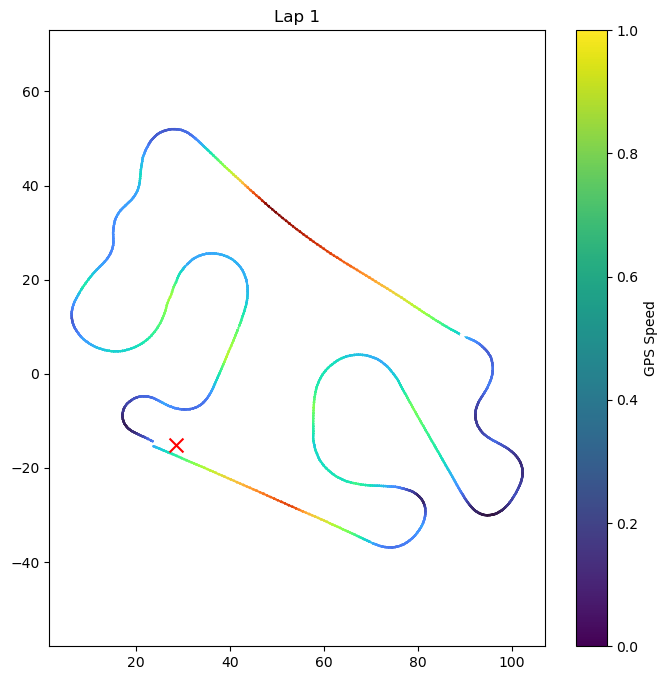

Lap 1: 5023 points
2


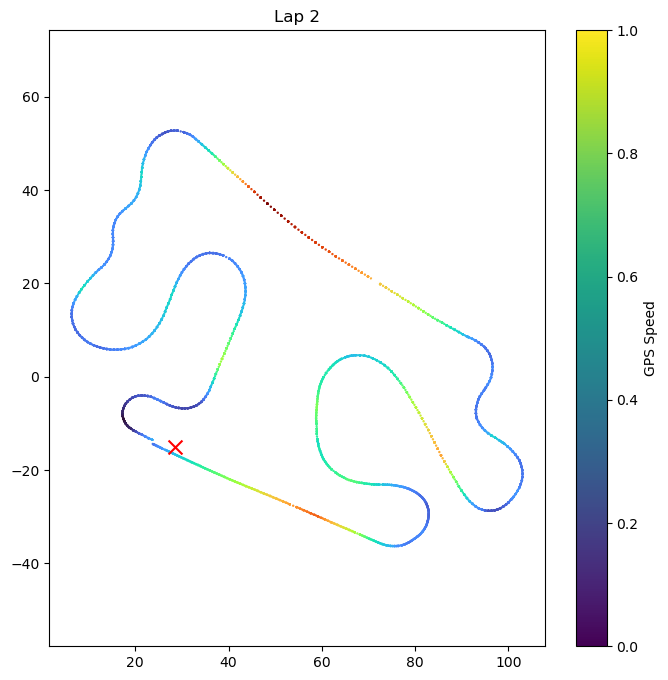

Lap 2: 4790 points
3


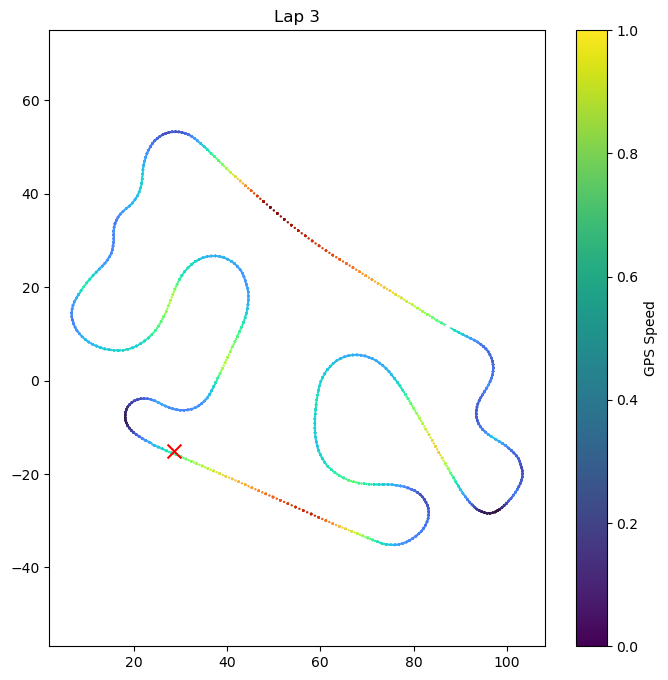

Lap 3: 4569 points
4


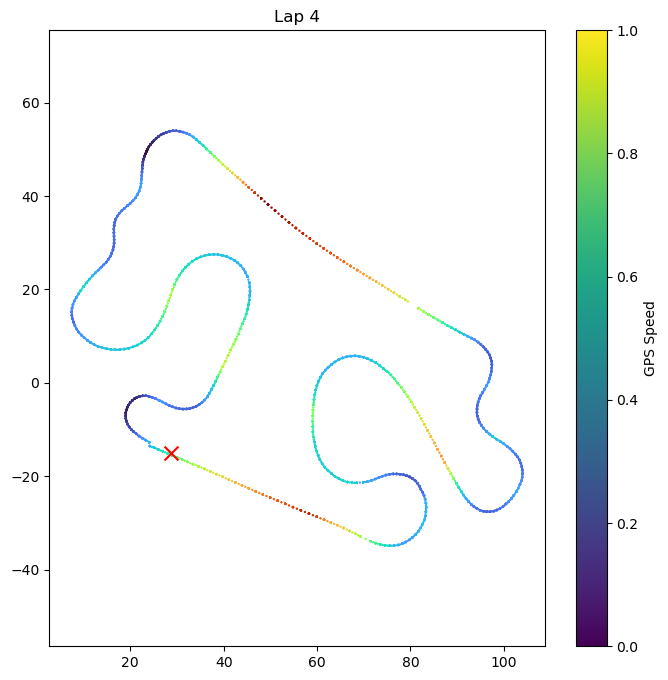

Lap 4: 4585 points
5


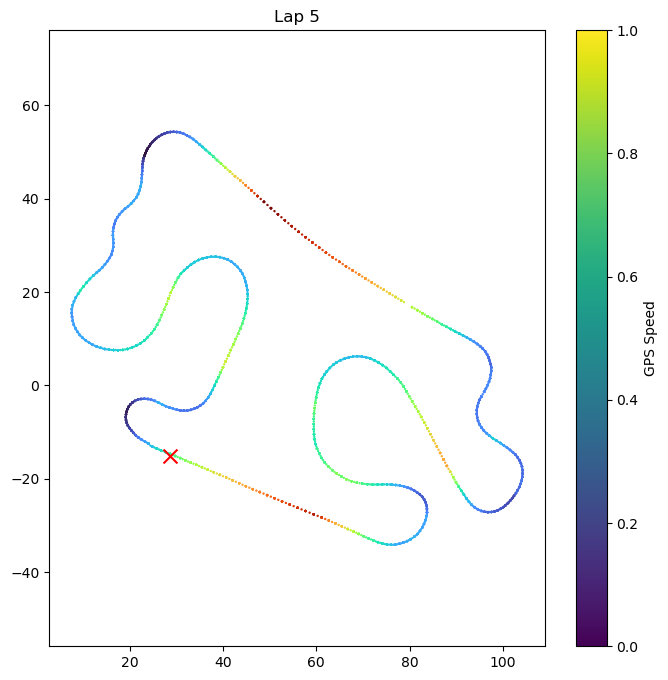

Lap 5: 4476 points
6


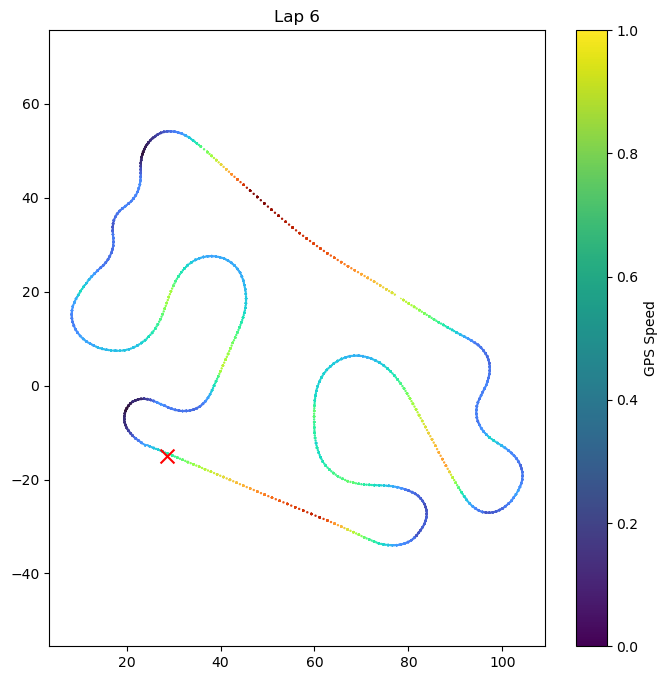

Lap 6: 4396 points
7


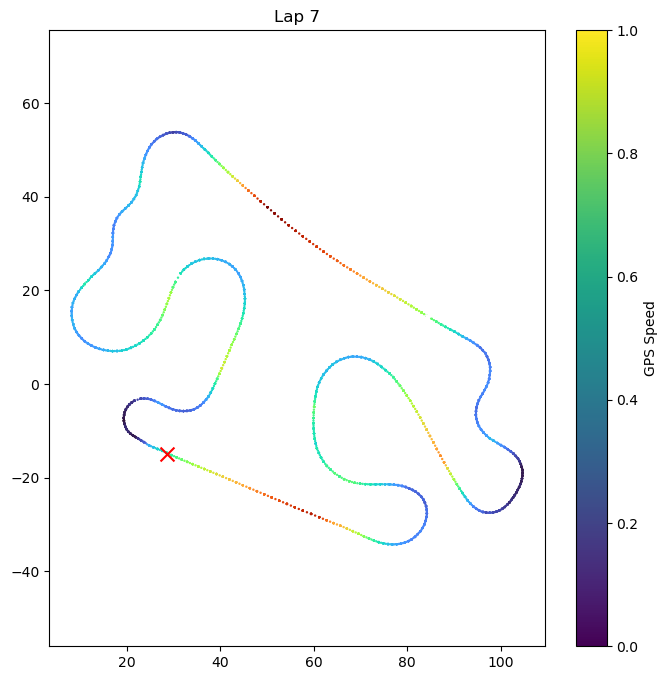

Lap 7: 4339 points
8


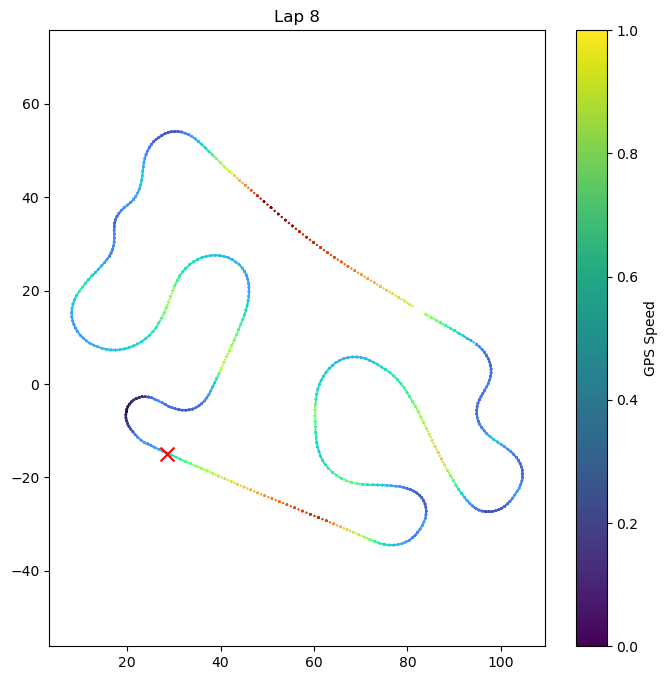

Lap 8: 4368 points
9


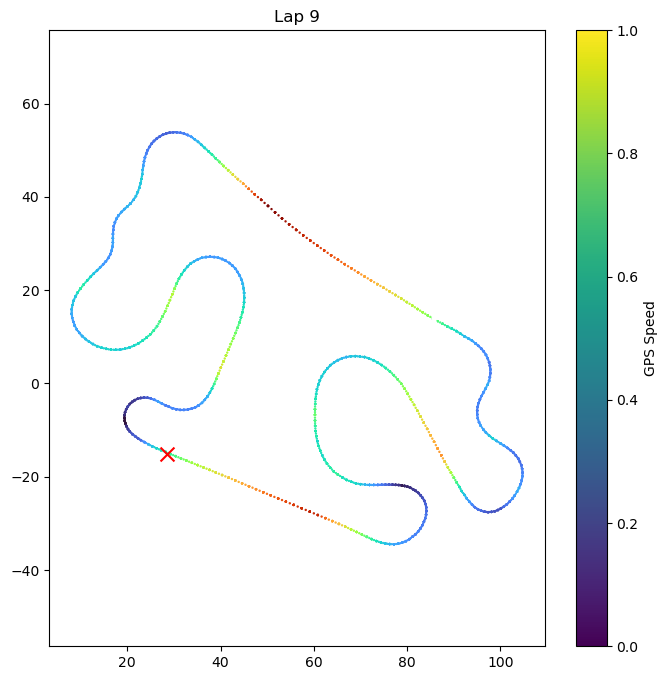

Lap 9: 4288 points
10


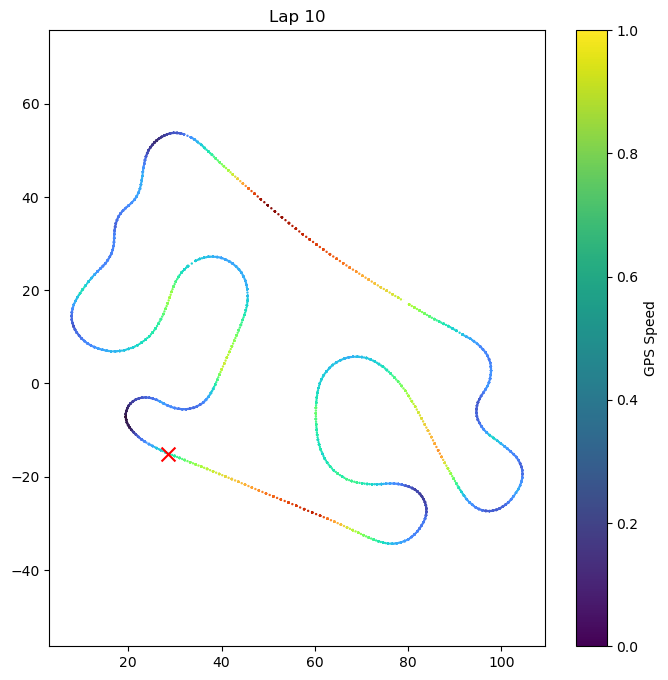

Lap 10: 4376 points
11


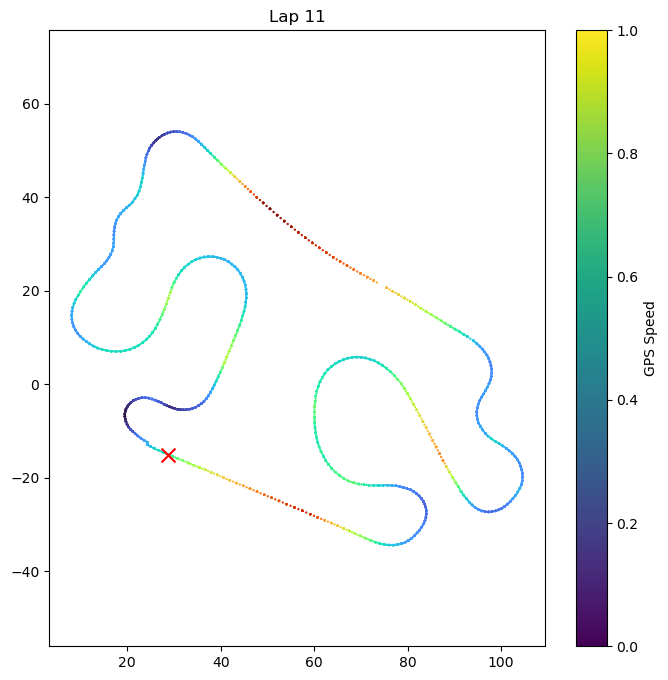

Lap 11: 4437 points
12


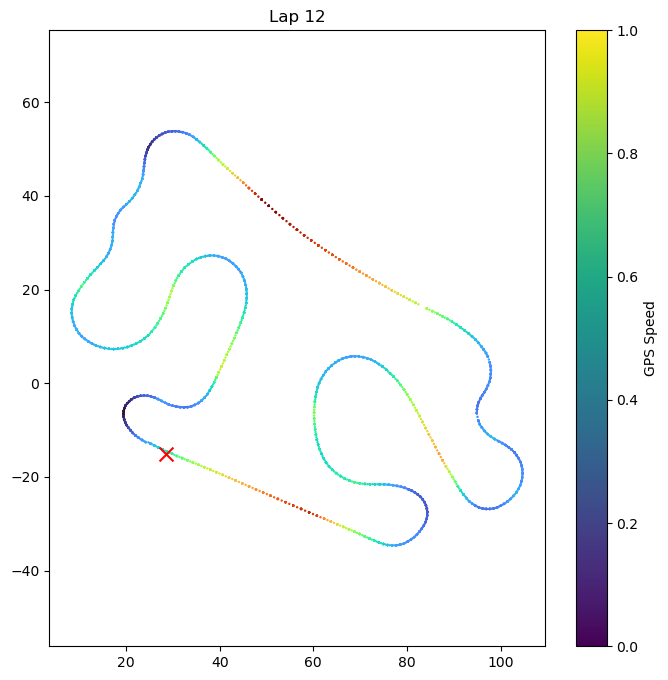

Lap 12: 4296 points
13


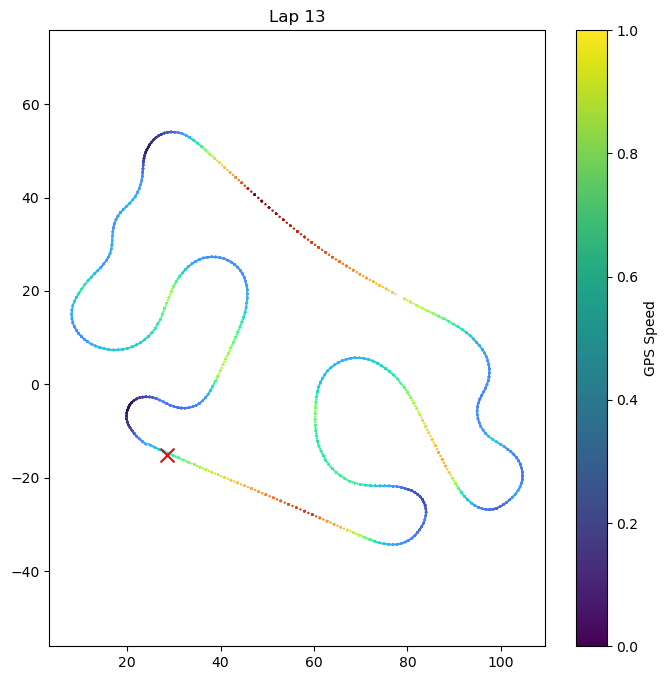

Lap 13: 4202 points
14


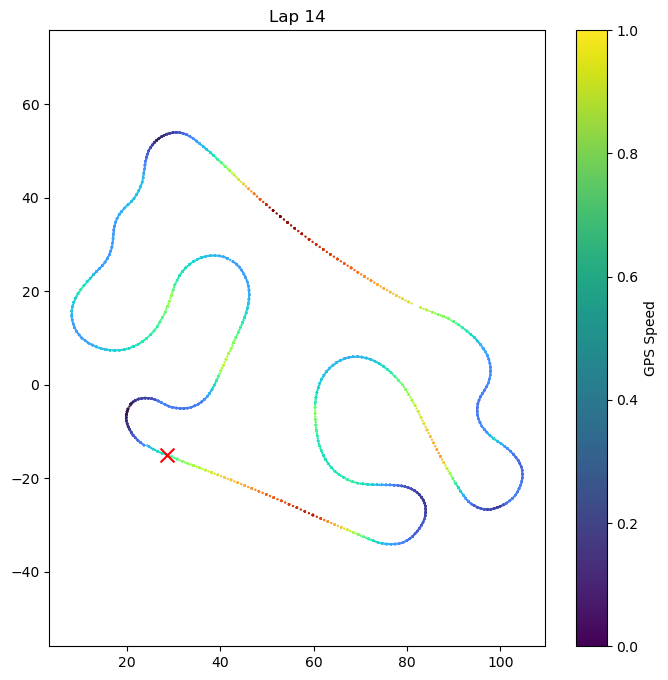

Lap 14: 4302 points
15


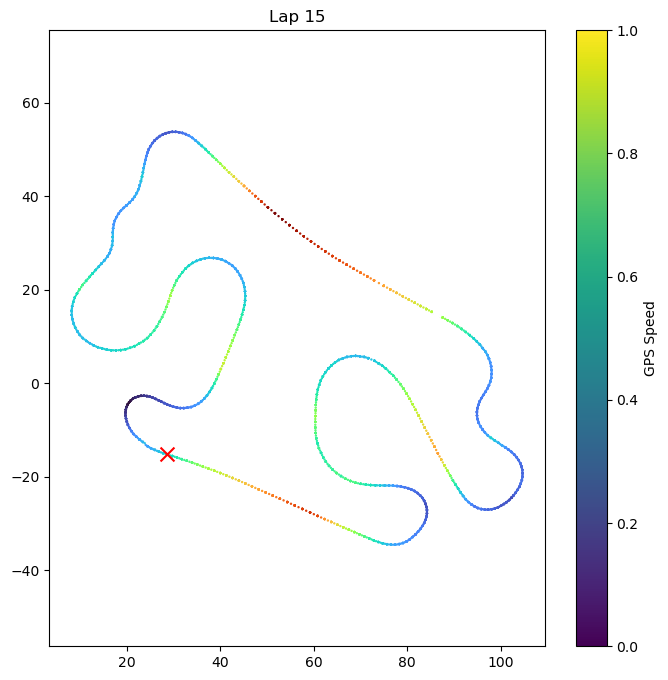

Lap 15: 4369 points
16


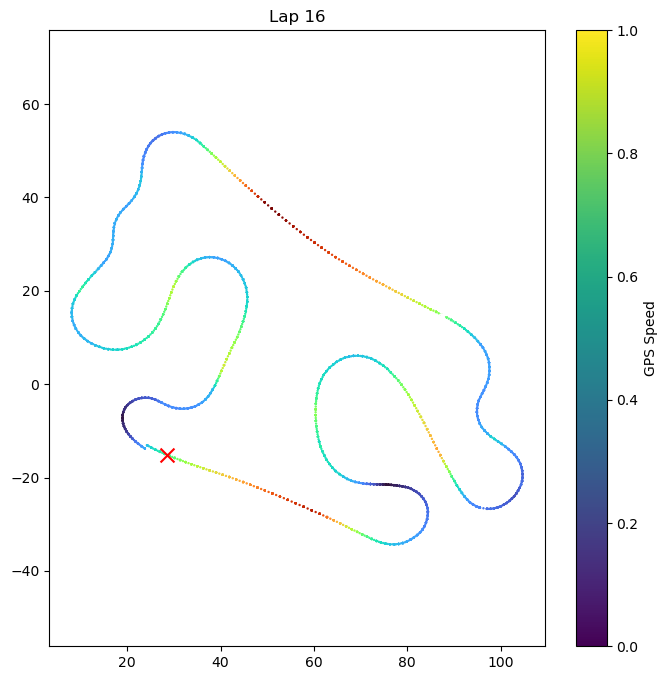

Lap 16: 4351 points
17


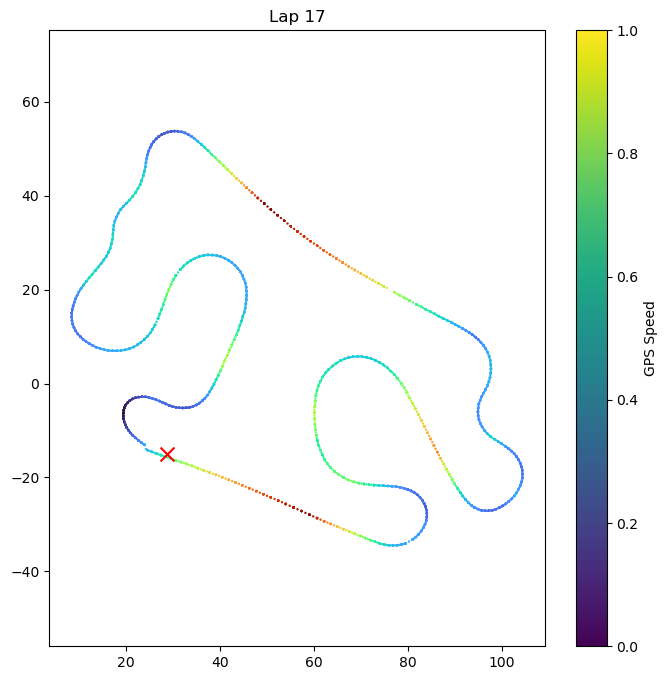

Lap 17: 4414 points
18


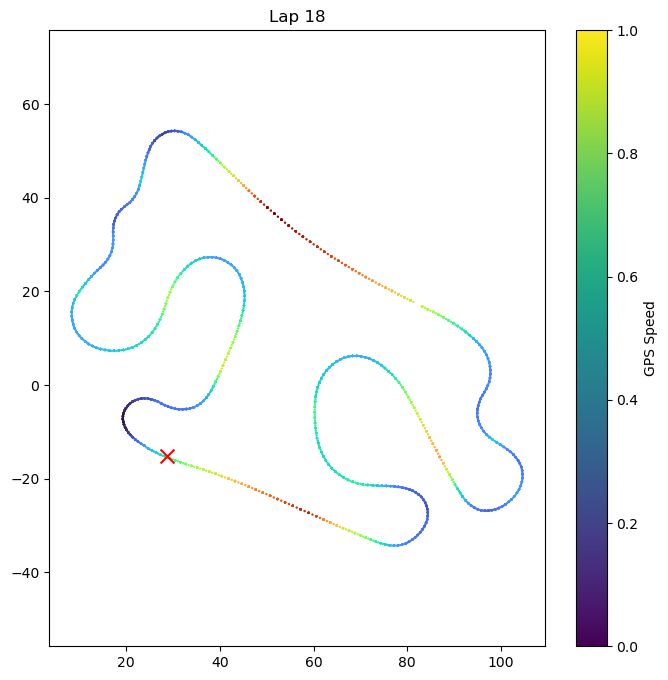

Lap 18: 4360 points
19


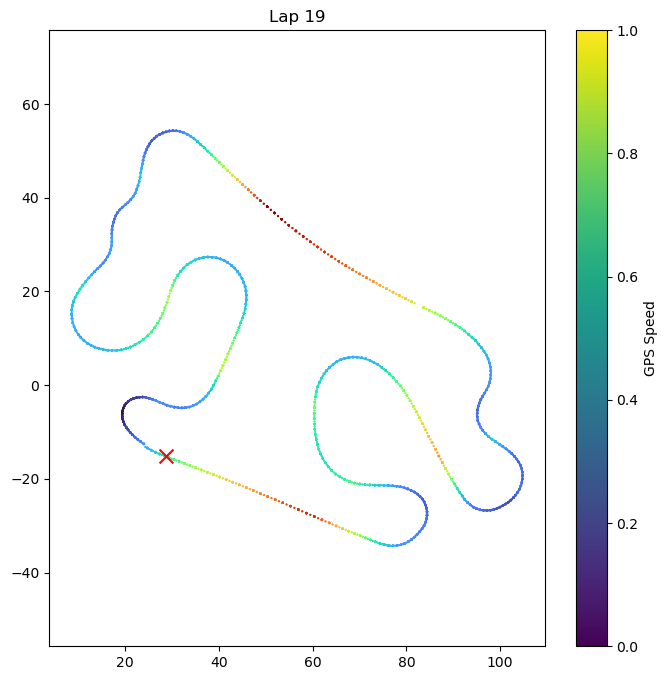

Lap 19: 4360 points
20


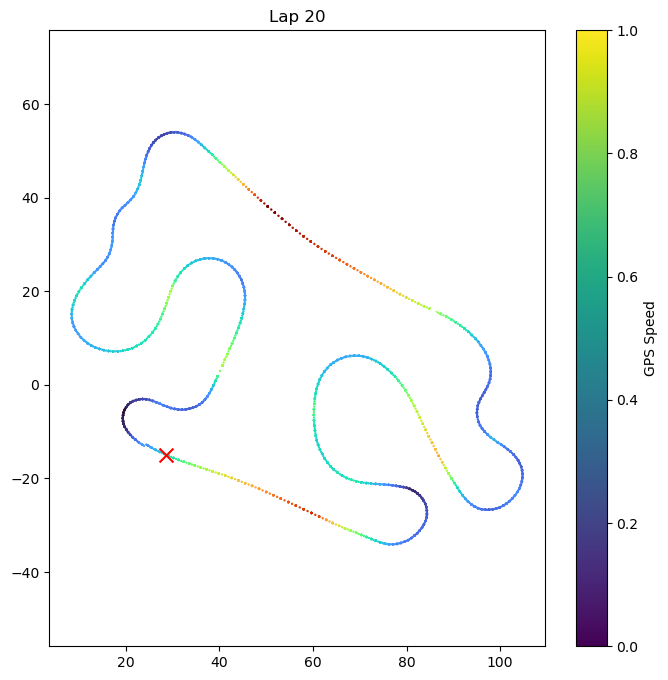

Lap 20: 4337 points
21


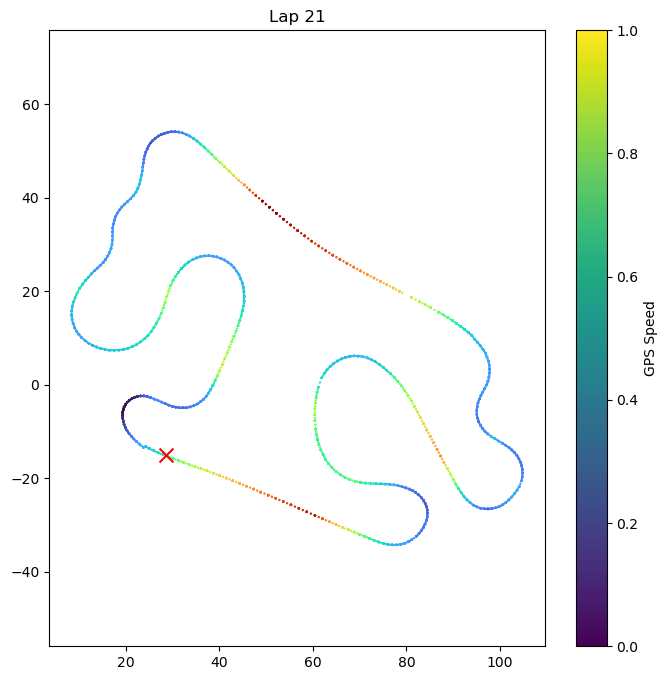

Lap 21: 4283 points
22


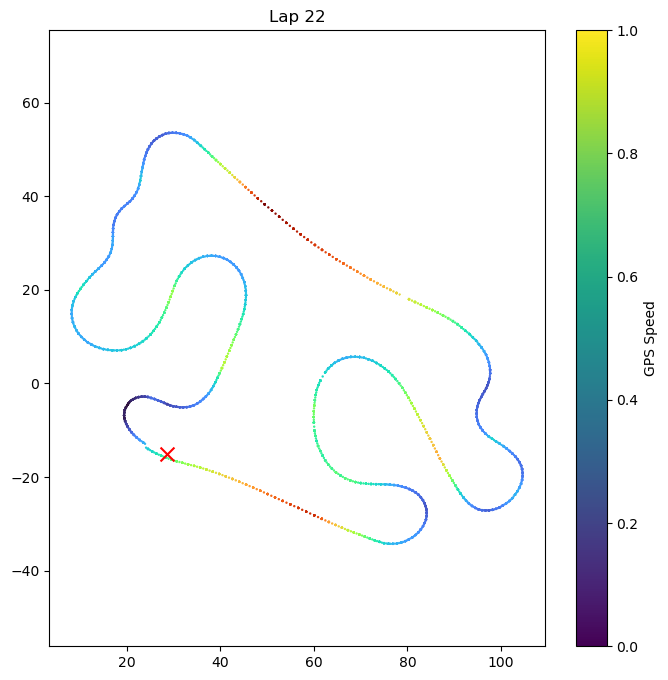

Lap 22: 4333 points
23


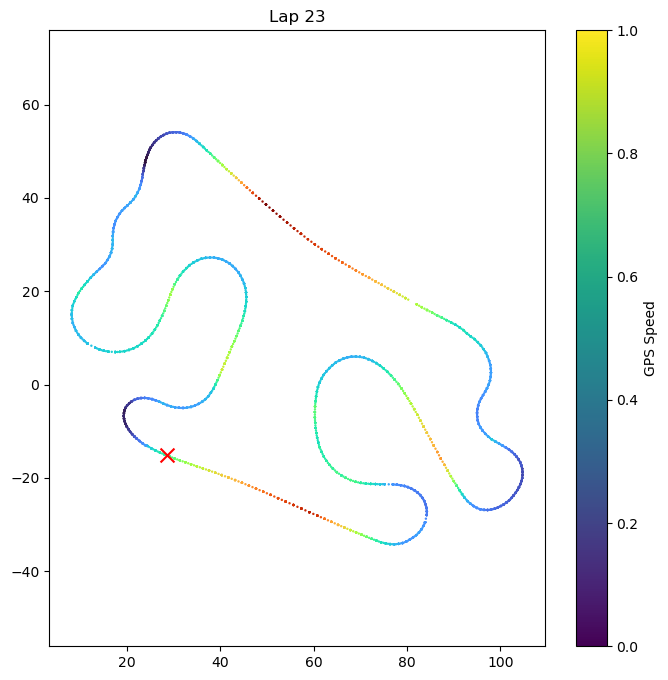

Lap 23: 4393 points
24


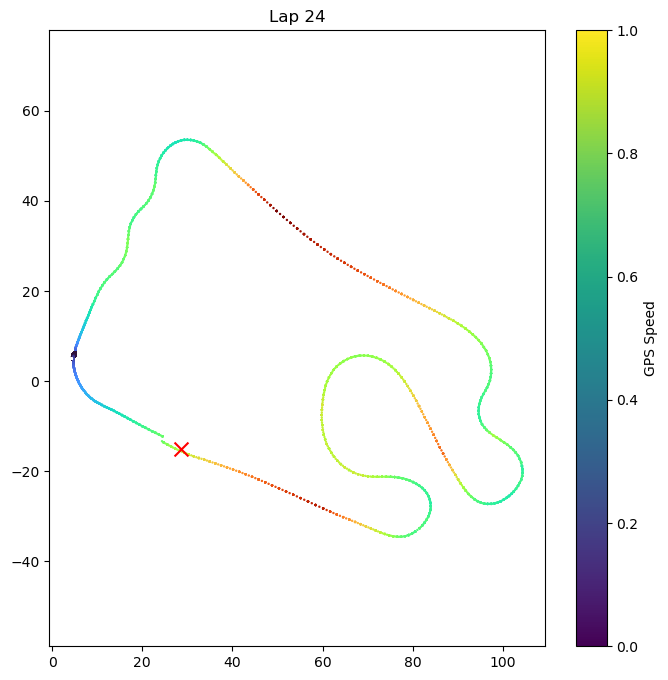

Lap 24: 24252 points
25


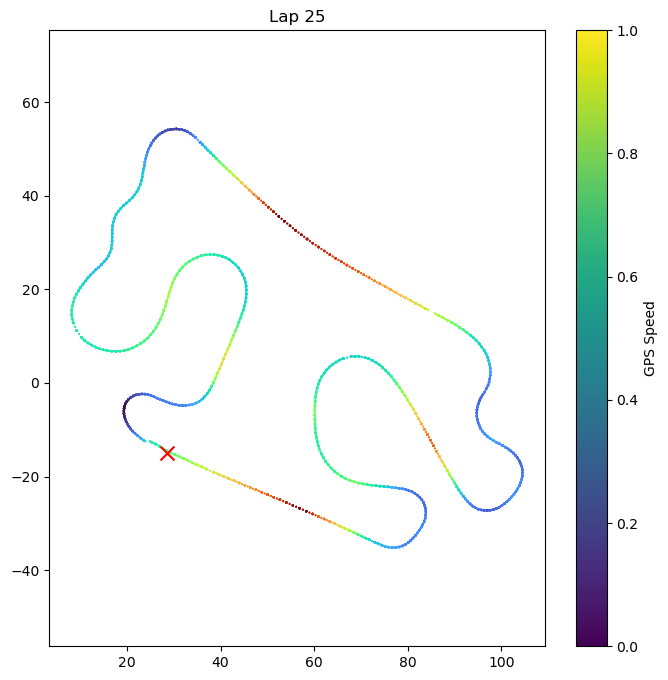

Lap 25: 4973 points
26


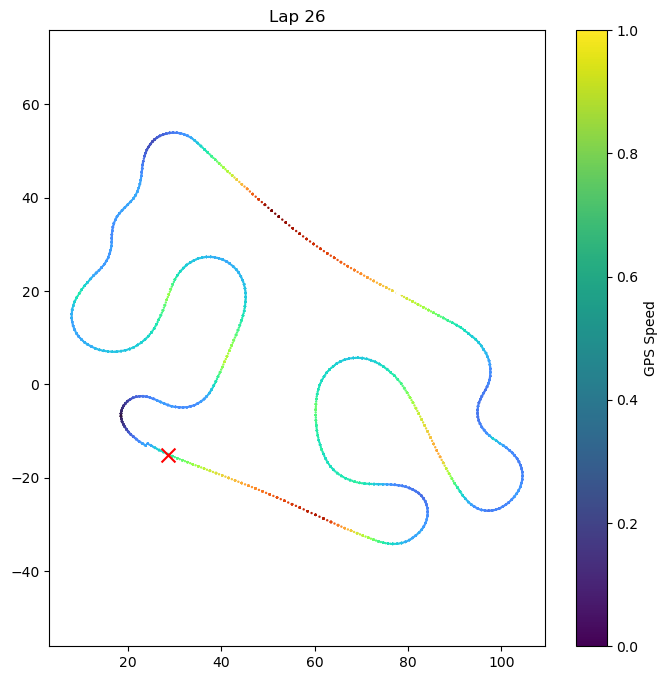

Lap 26: 4441 points
27


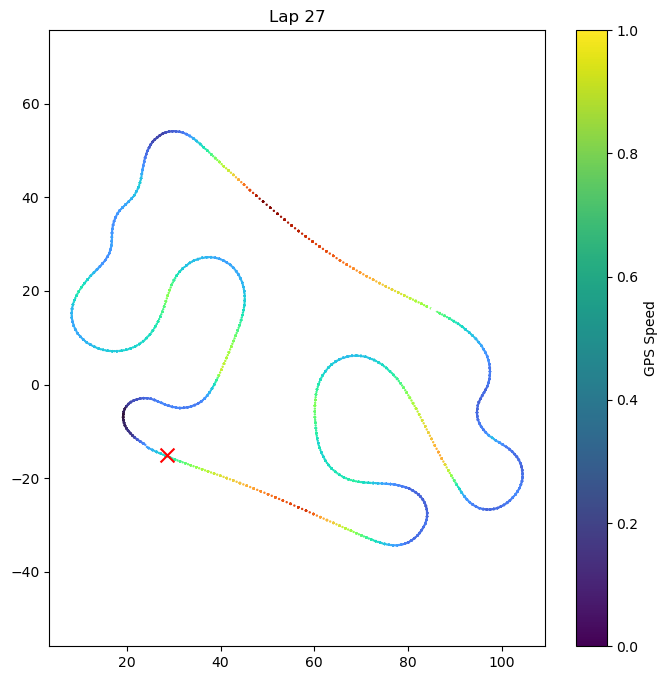

Lap 27: 4345 points
28


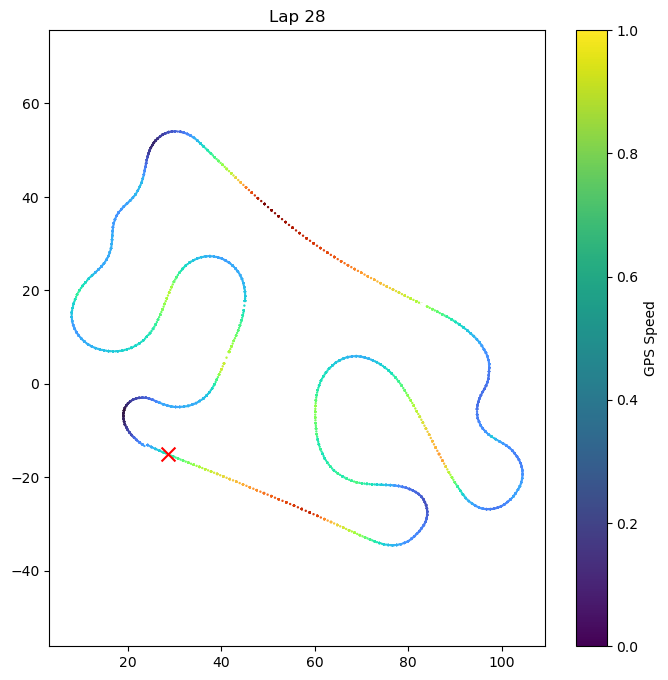

Lap 28: 4352 points
29


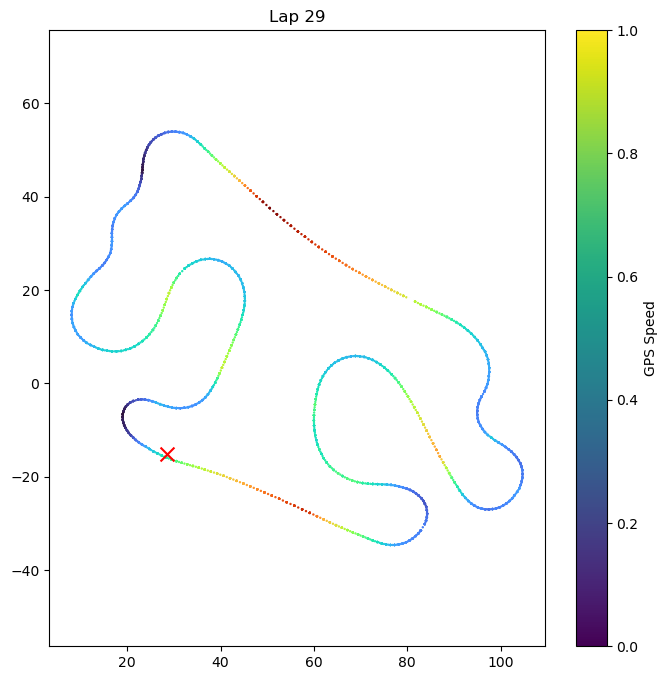

Lap 29: 4376 points
30


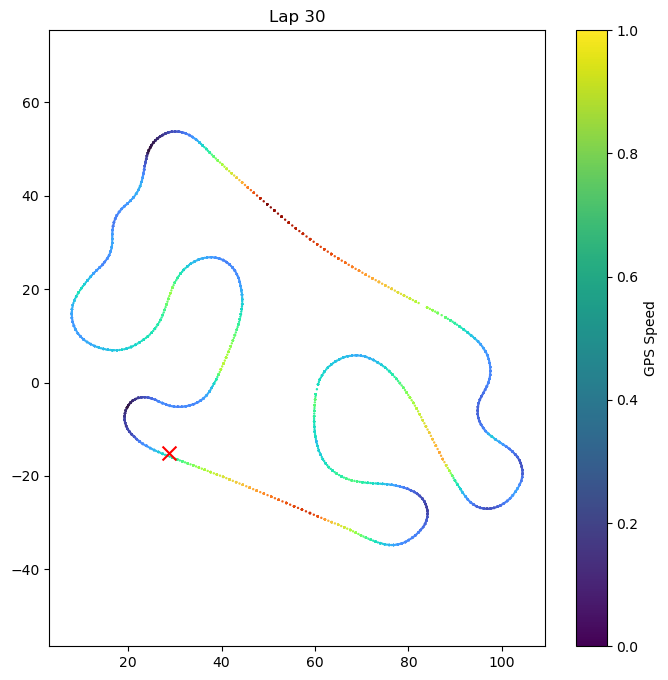

Lap 30: 4292 points
31


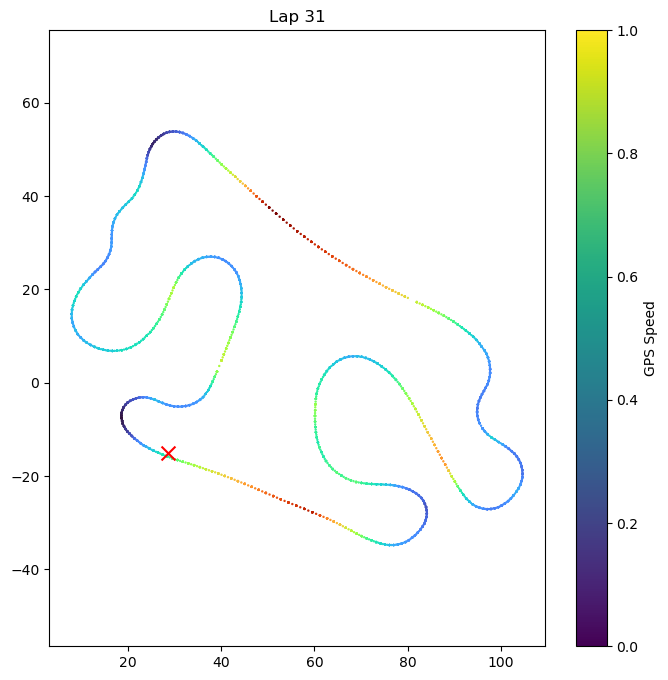

Lap 31: 4306 points
32


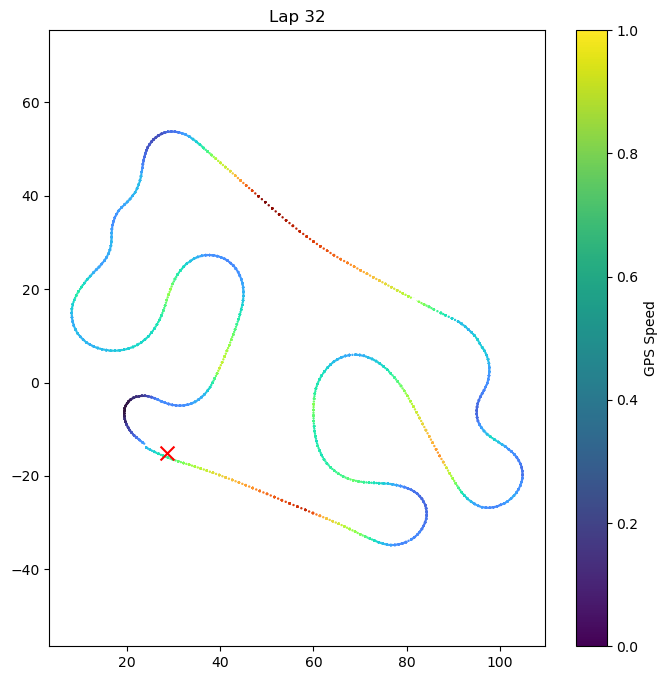

Lap 32: 4366 points
33


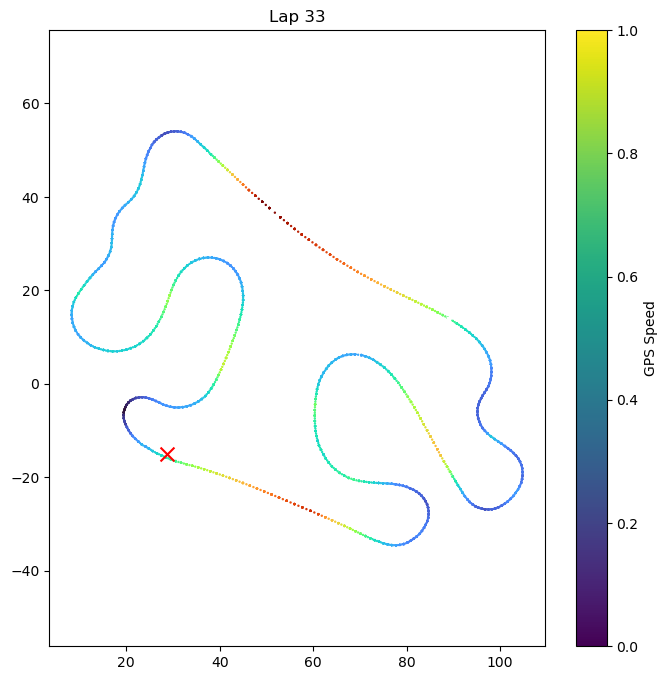

Lap 33: 4360 points
34


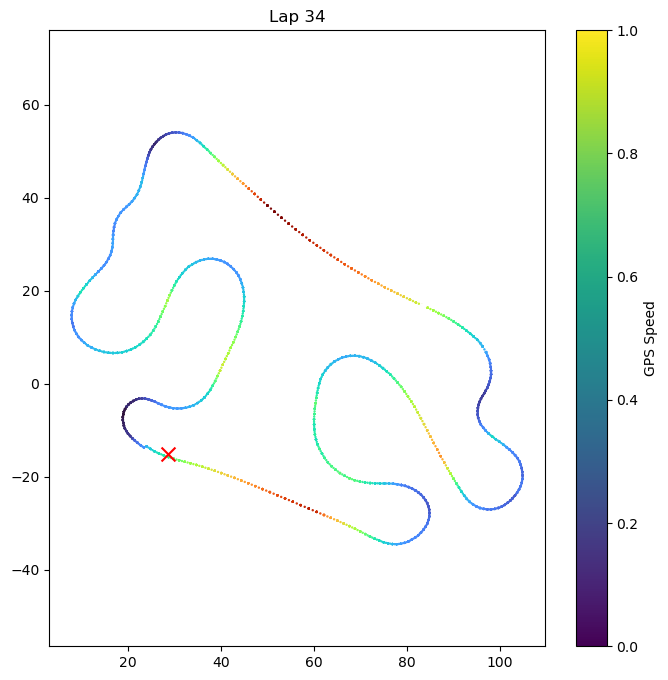

Lap 34: 4361 points
35


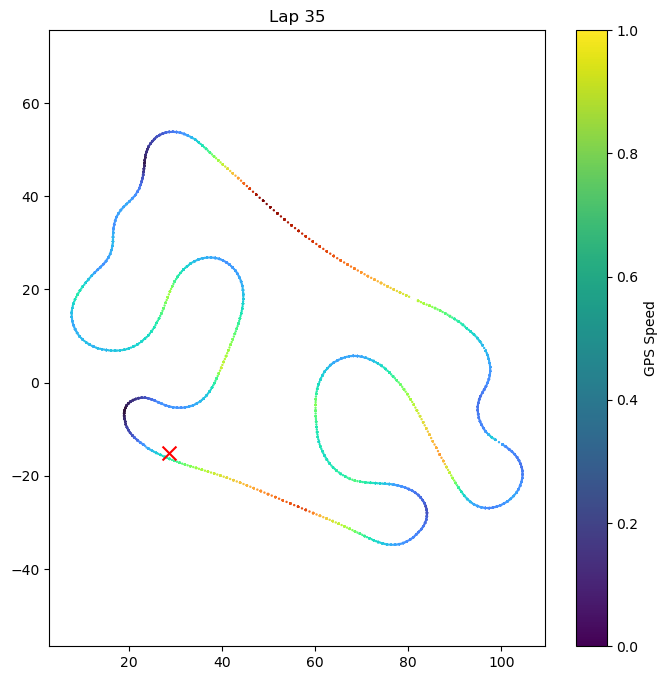

Lap 35: 4327 points
36


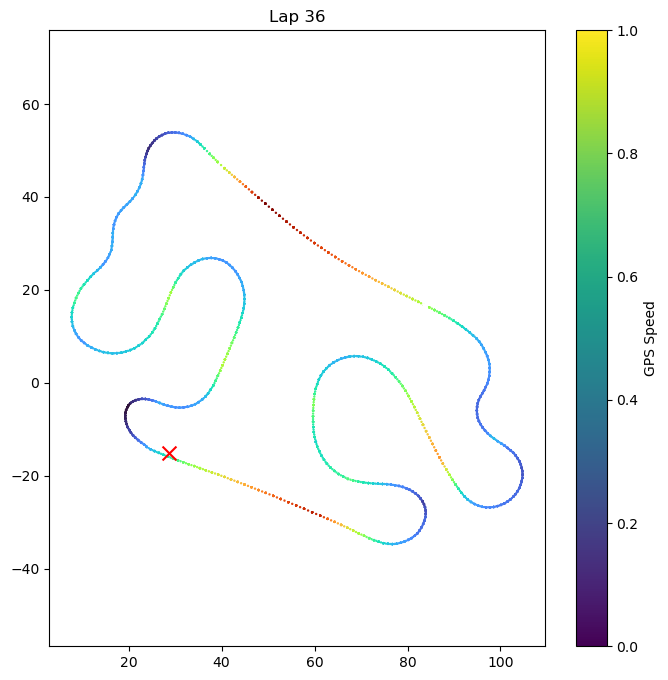

Lap 36: 4314 points
37


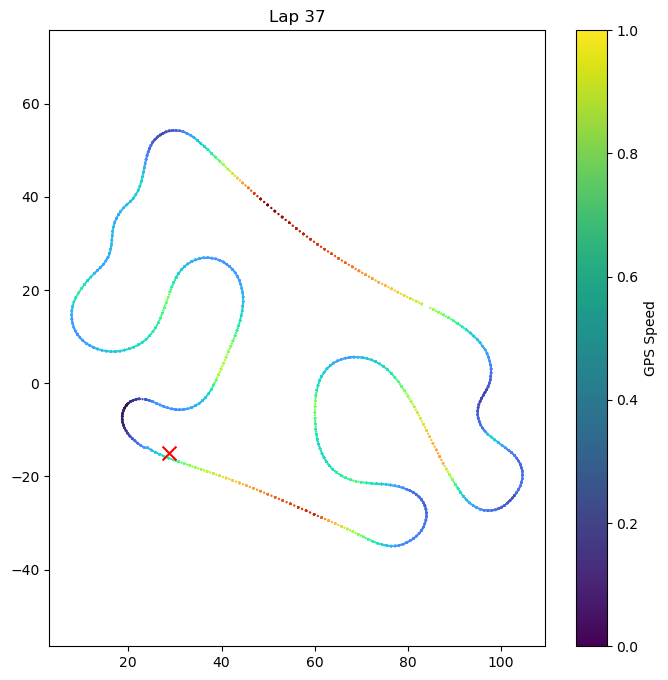

Lap 37: 4299 points
38


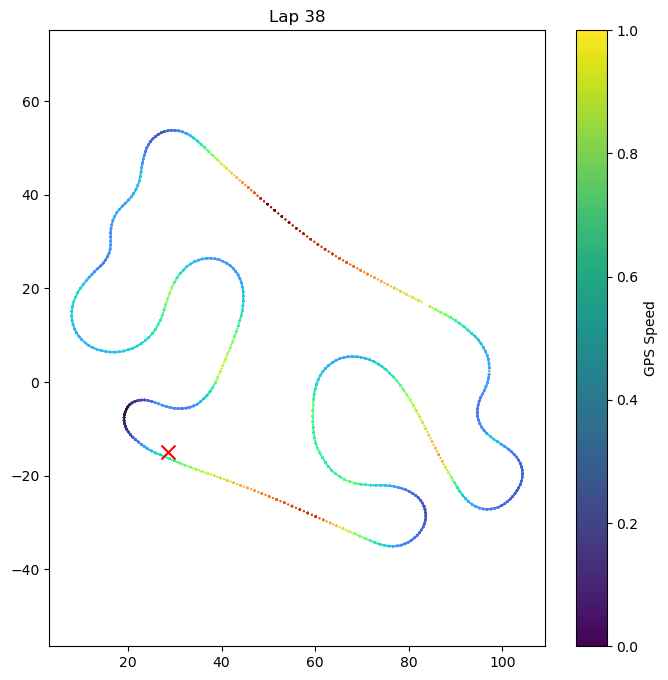

Lap 38: 4236 points
39


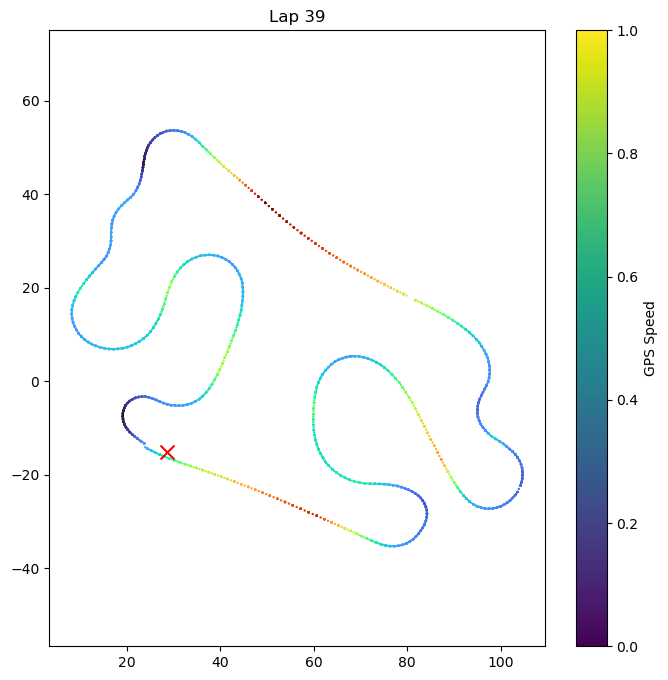

Lap 39: 4278 points
40


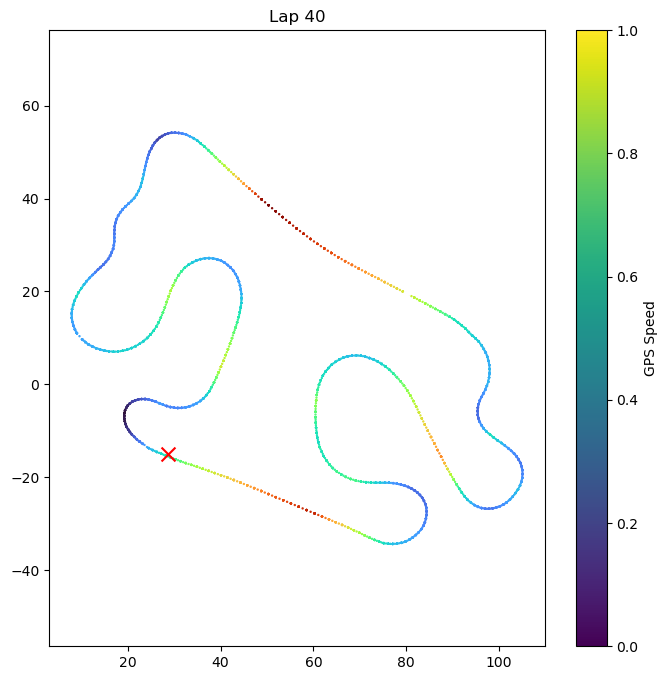

Lap 40: 4281 points
41


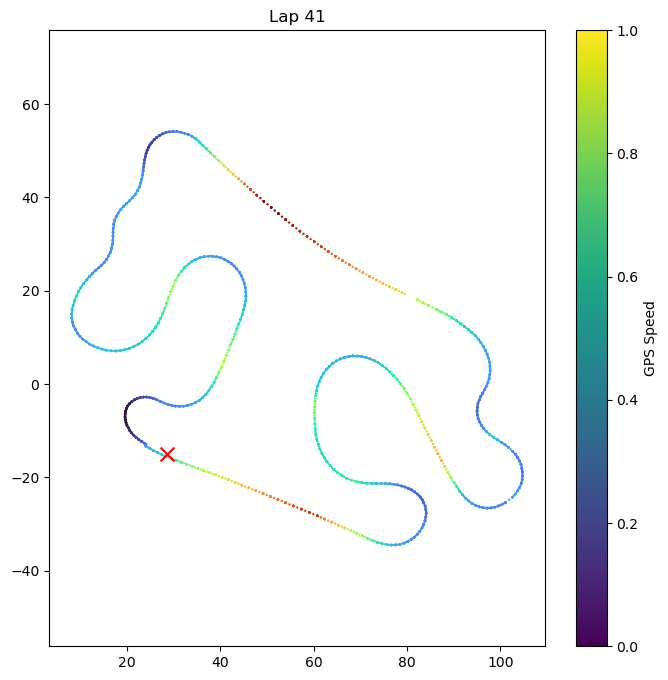

Lap 41: 4276 points
42


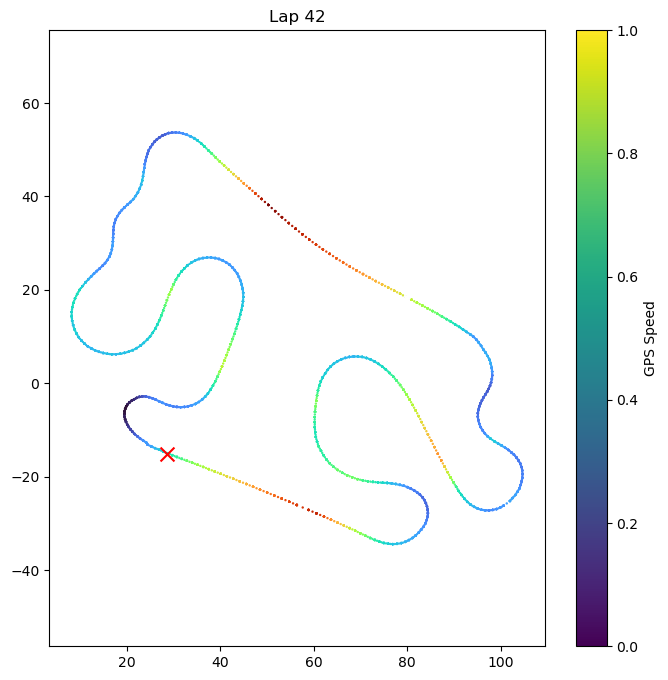

Lap 42: 4433 points
43


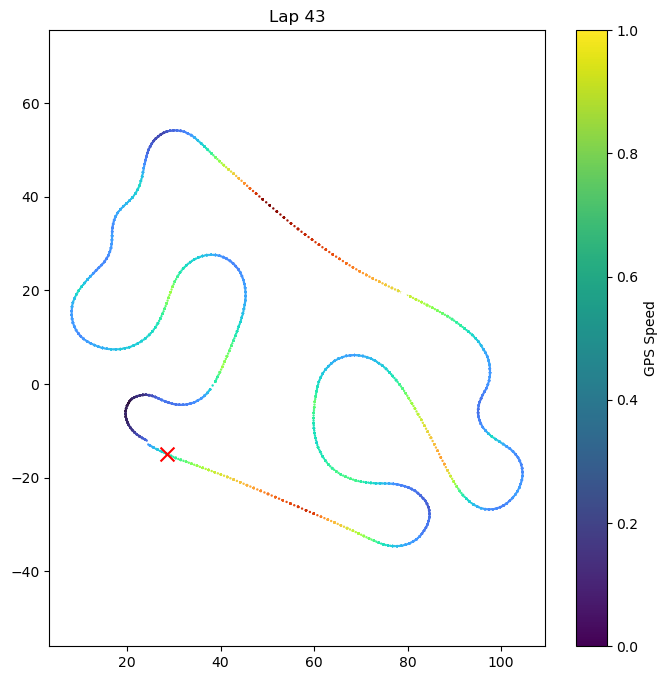

Lap 43: 4363 points
44


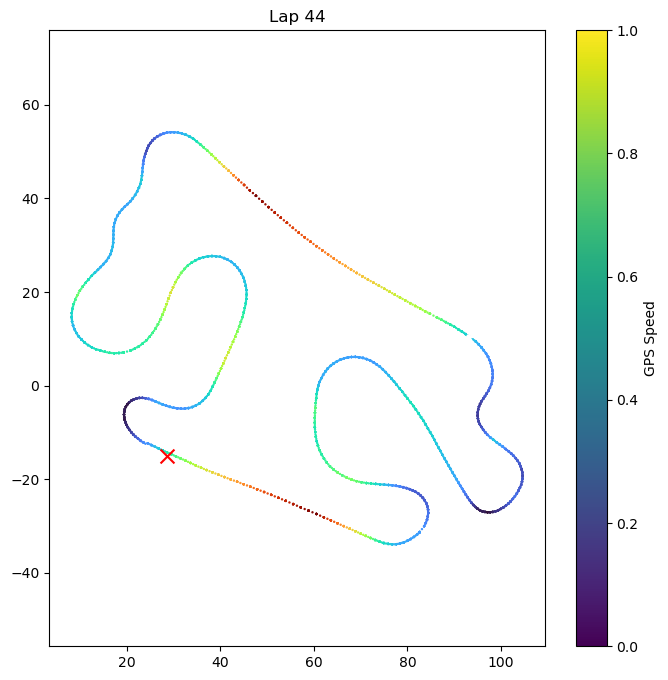

Lap 44: 4750 points
45


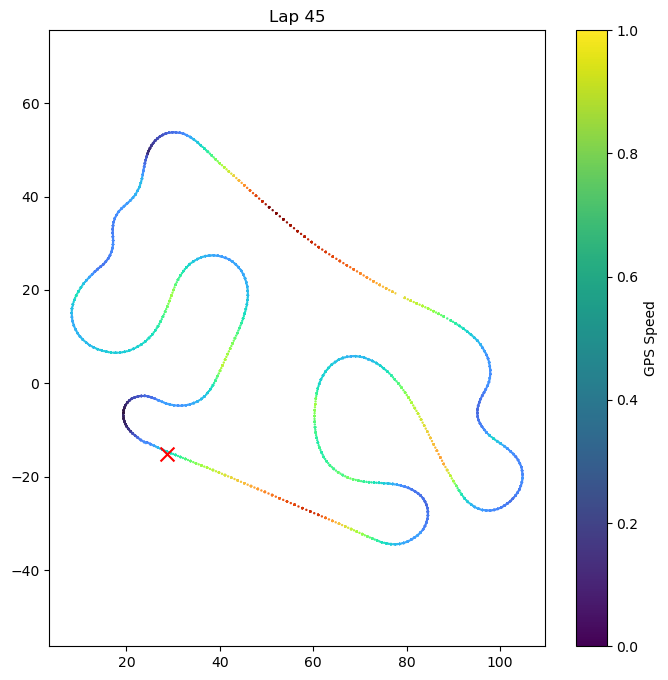

Lap 45: 4354 points
46


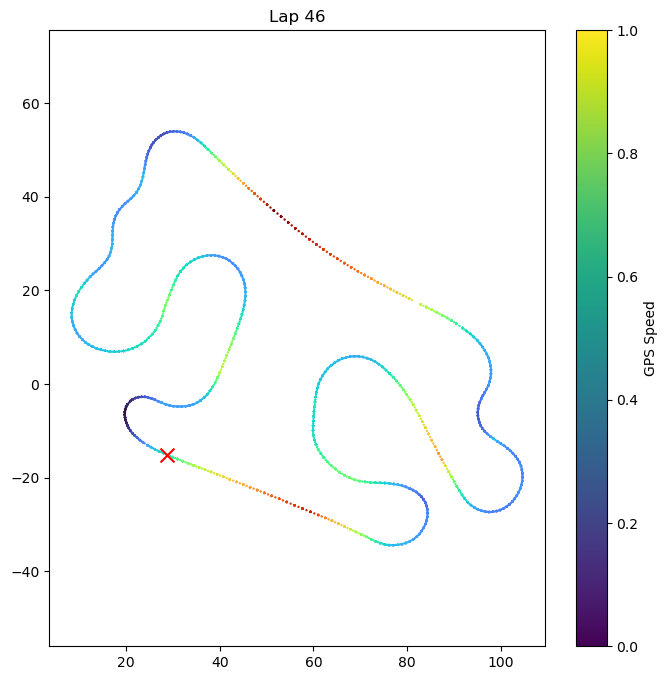

Lap 46: 4380 points
47


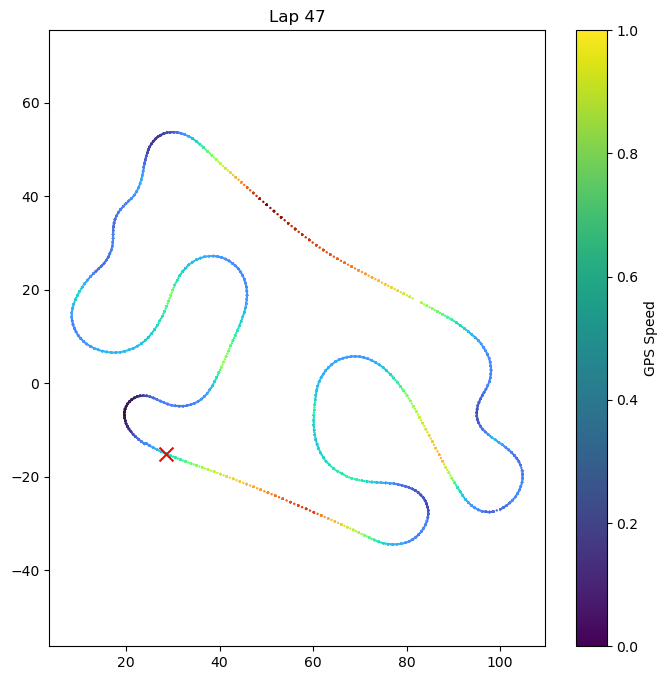

Lap 47: 4395 points


In [11]:
streightStart = 0
streightEnd = 4000


# Start/finish position
lapStart = FindLapStart(gpsdf) #4960
xStart = gpsdf["x"].iloc[lapStart]
yStart = gpsdf["y"].iloc[lapStart]

# Detect crossings
radius = 5
minLapTime = 15

gpsdf = gpsdf.reset_index(drop=True)

distance = np.hypot(gpsdf["x"] - xStart, gpsdf["y"] - yStart)
inside = distance < radius

crossings = np.where(inside & ~inside.shift(1, fill_value=False))[0]

# Remove repeated crossings
validCrossings = [crossings[0]]

for crossing in crossings[1:]:
    if gpsdf["Time"].iloc[crossing] - gpsdf["Time"].iloc[validCrossings[-1]] > minLapTime:
        validCrossings.append(crossing)

# Separate and plot laps
laps = []

maxLapsToShow = 100
lapsToShow = min(maxLapsToShow, len(validCrossings) - 1)
for i in range(lapsToShow):
    lap = gpsdf.iloc[validCrossings[i]:validCrossings[i + 1]].copy()
    laps.append(lap)
    print(len(laps))

    plt.figure(figsize=(8, 8))

    plt.scatter(
        lap["x"],
        lap["y"],
        c=lap["GPS Speed"],
        cmap="turbo",
        s=0.5
    )

    plt.scatter(
        gpsdf["x"].iloc[lapStart],
        gpsdf["y"].iloc[lapStart],
        color="red",
        s=100,
        marker="x",
        label="Automatic Lap Start"
    )

        # Arrow showing direction of travel
    arrowIndex = len(lap) // 2
    arrowStep = 20

    plt.annotate(
        "",
        xy=(lap["x"].iloc[arrowIndex + arrowStep],
            lap["y"].iloc[arrowIndex + arrowStep]),
        xytext=(lap["x"].iloc[arrowIndex],
                lap["y"].iloc[arrowIndex]),
        arrowprops=dict(
            arrowstyle="->",
            color="white",
            lw=2,
            mutation_scale=20
        )
    )

    plt.title(f"Lap {i + 1}")
    plt.colorbar(label="GPS Speed")
    plt.axis("equal")
    plt.show()

    print(f"Lap {i + 1}: {len(lap)} points")

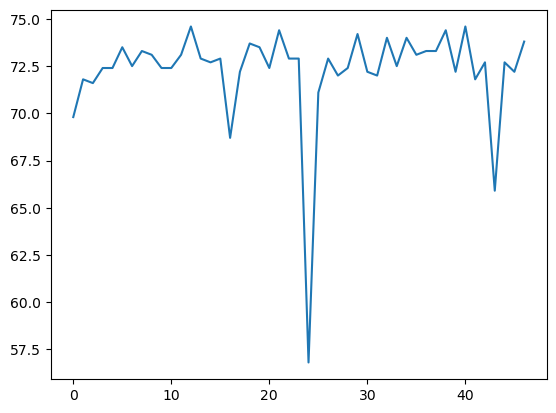

In [19]:
speeds = []
for i in range(lapsToShow):
    lap = gpsdf.iloc[validCrossings[i]:validCrossings[i + 1]].copy()
    speed = (max(lap["GPS Speed"]))

    speeds.append(speed)


plt.plot(range(len(speeds)), speeds)
#print(max(speeds)/ 1.6)



In [9]:
def CalculateCurvature(lap, window=51, polyOrder=3):


    x = lap["x"].to_numpy()
    y = lap["y"].to_numpy()

    # Smooth GPS coordinates
    x = savgol_filter(x, window, polyOrder)
    y = savgol_filter(y, window, polyOrder)

    # Calculate derivatives
    dx = np.gradient(x)
    dy = np.gradient(y)

    ddx = np.gradient(dx)
    ddy = np.gradient(dy)

    # Calculate curvature
    curvature = (dx * ddy - dy * ddx) / (
        dx**2 + dy**2
    )**1.5

    lap["Curvature"] = curvature

    return laps

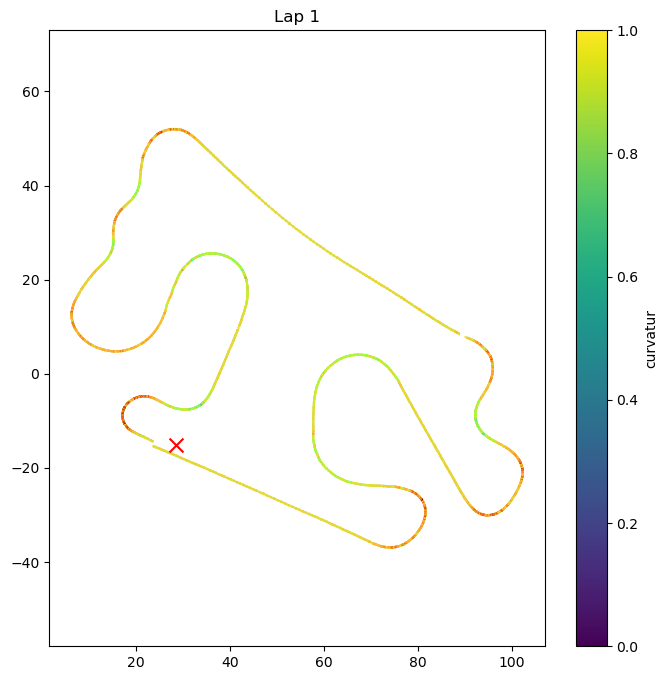

Lap 1: 5023 points


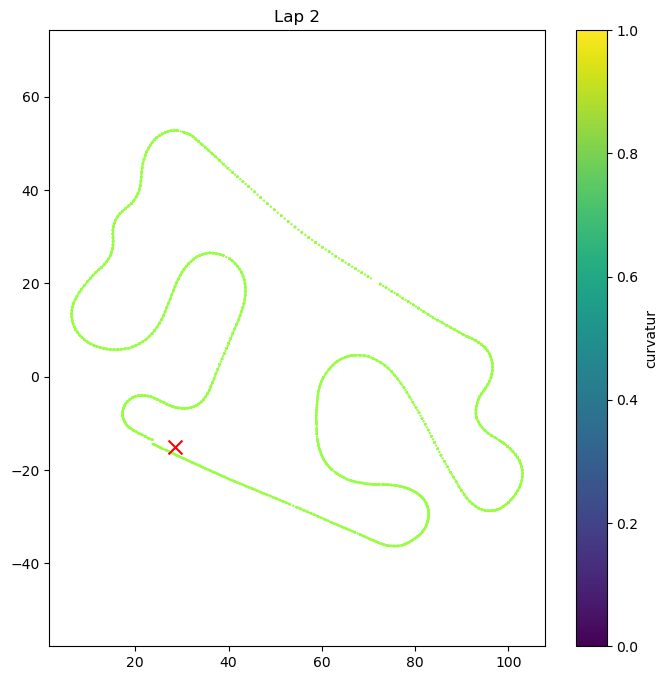

Lap 2: 4790 points


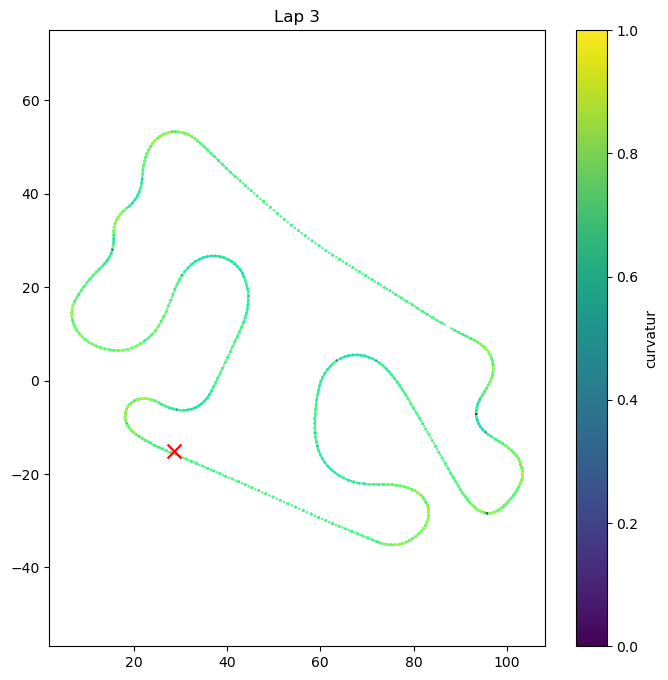

Lap 3: 4569 points


In [10]:
maxLapsToShow = 3


lapsToShow = min(maxLapsToShow, len(validCrossings) - 1)
for i in range(lapsToShow):
    lap = gpsdf.iloc[validCrossings[i]:validCrossings[i + 1]].copy()
    CalculateCurvature(lap, window=25, polyOrder=3)


    plt.figure(figsize=(8, 8))

    plt.scatter(
        lap["x"],
        lap["y"],
        c=lap["Curvature"],
        cmap="turbo",
        s=0.5
    )

    plt.scatter(
        gpsdf["x"].iloc[lapStart],
        gpsdf["y"].iloc[lapStart],
        color="red",
        s=100,
        marker="x",
        label="Automatic Lap Start"
    )

        # Arrow showing direction of travel
    arrowIndex = len(lap) // 2
    arrowStep = 20

    plt.annotate(
        "",
        xy=(lap["x"].iloc[arrowIndex + arrowStep],
            lap["y"].iloc[arrowIndex + arrowStep]),
        xytext=(lap["x"].iloc[arrowIndex],
                lap["y"].iloc[arrowIndex]),
        arrowprops=dict(
            arrowstyle="->",
            color="white",
            lw=2,
            mutation_scale=20
        )
    )

    plt.title(f"Lap {i + 1}")
    plt.colorbar(label="curvatur")
    plt.axis("equal")
    plt.show()

    print(f"Lap {i + 1}: {len(lap)} points")

### Preassure

### Aero Balance

### Suspension Data
- roll
- suspension geometry (compression)